In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [87]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename, encoding='utf-8-sig')

print("Dataset Shape:", df.shape)
print(df.head())

Saving breast_cancer_dataset_with_quality_issues_UTF8.csv to breast_cancer_dataset_with_quality_issues_UTF8 (1).csv
Dataset Shape: (282, 10)
     age mefalsepause tumor-size inv-falsedes falsede-caps  deg-malig breast  \
0  40-49   premefalse      15-19          0-2         True        3.0  right   
1  50-59         ge40      15-19          0-2        False        1.0  right   
2  50-59         ge40      35-39          0-2        False        2.0   left   
3  40-49   premefalse      35-39          0-2         True        3.0  right   
4  40-49   premefalse      30-34          3-5         True        2.0   left   

  breast-quad irradiat                    class  
0     left_up    False        recurrence-events  
1     central    False  false-recurrence-events  
2    left_low    False        recurrence-events  
3    left_low     True  false-recurrence-events  
4    right_up    False        recurrence-events  


In [88]:
# 1. Dataset information
print("DATASET INFORMATION")
print(df.info())

# 2. Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 4. Duplicate records
print("\nDUPLICATE RECORDS:", df.duplicated().sum())

# 5. Statistical summary
print("\nSTATISTICAL SUMMARY")
print(df.describe(include='all'))

# 6. Unique values in each column
print("\nUNIQUE VALUES")
for col in df.columns:
    print(col, ":", df[col].unique())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 282 entries, 0 to 281
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           280 non-null    object 
 1   mefalsepause  275 non-null    object 
 2   tumor-size    281 non-null    object 
 3   inv-falsedes  280 non-null    object 
 4   falsede-caps  273 non-null    object 
 5   deg-malig     279 non-null    float64
 6   breast        282 non-null    object 
 7   breast-quad   280 non-null    object 
 8   irradiat      281 non-null    object 
 9   class         282 non-null    object 
dtypes: float64(1), object(9)
memory usage: 22.2+ KB
None

MISSING VALUES
age             2
mefalsepause    7
tumor-size      1
inv-falsedes    2
falsede-caps    9
deg-malig       3
breast          0
breast-quad     2
irradiat        1
class           0
dtype: int64

Total Missing Values: 27

DUPLICATE RECORDS: 10

STATISTICAL SUMMARY
          age mefalsep

In [89]:
# Check duplicates before removal
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Check duplicates after removal
print("Duplicates after cleaning:", df.duplicated().sum())

# Check new dataset shape
print("Dataset Shape:", df.shape)

Duplicates before cleaning: 10
Duplicates after cleaning: 0
Dataset Shape: (272, 10)


In [90]:
# Check missing values
print("Missing values before treatment:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values before treatment:
age             2
mefalsepause    4
tumor-size      1
inv-falsedes    2
falsede-caps    9
deg-malig       2
breast          0
breast-quad     2
irradiat        1
class           0
dtype: int64

Total missing values: 23


In [91]:
# Categorical columns: Fill missing values with mode
categorical_columns = [
    'age',
    'mefalsepause',
    'tumor-size',
    'inv-falsedes',
    'falsede-caps',
    'breast',
    'breast-quad',
    'irradiat'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Numerical column: Fill missing values with median
df['deg-malig'] = df['deg-malig'].fillna(df['deg-malig'].median())

# Check missing values after treatment
print("Missing values after treatment:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values after treatment:
age             0
mefalsepause    0
tumor-size      0
inv-falsedes    0
falsede-caps    0
deg-malig       0
breast          0
breast-quad     0
irradiat        0
class           0
dtype: int64

Total missing values: 0


/tmp/ipykernel_1591/68101908.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(df[col].mode()[0])


In [92]:
# Correct invalid categorical values

invalid_values = {
    'age': ['120-129'],
    'tumor-size': ['55-59'],
    'inv-falsedes': ['30-32'],
    'mefalsepause': ['unknown-category'],
    'breast': ['middle'],
    'irradiat': ['maybe']
}

for col, invalid in invalid_values.items():
    valid_mode = df.loc[~df[col].isin(invalid), col].mode()[0]
    df.loc[df[col].isin(invalid), col] = valid_mode

# Correct invalid numerical values
valid_median = df.loc[df['deg-malig'].isin([1, 2, 3]), 'deg-malig'].median()

df.loc[~df['deg-malig'].isin([1, 2, 3]), 'deg-malig'] = valid_median

# Verify corrections
print("Invalid values after treatment:")

for col, invalid in invalid_values.items():
    print(col, ":", df[col].isin(invalid).sum())

print("deg-malig invalid values:",
      (~df['deg-malig'].isin([1, 2, 3])).sum())

Invalid values after treatment:
age : 0
tumor-size : 0
inv-falsedes : 0
mefalsepause : 0
breast : 0
irradiat : 0
deg-malig invalid values: 0


In [93]:
# Standardize categorical text values
df['mefalsepause'] = df['mefalsepause'].str.strip().str.lower()

df['breast-quad'] = df['breast-quad'].str.strip().str.lower()

df['breast'] = df['breast'].str.strip().str.lower()

# Check unique values after standardization
for col in ['mefalsepause', 'breast-quad', 'breast']:
    print("\n", col)
    print(df[col].unique())


 mefalsepause
['premefalse' 'ge40' 'lt40']

 breast-quad
['left_up' 'central' 'left_low' 'right_up' 'right_low']

 breast
['right' 'left']


In [94]:

# 1. Dataset shape
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

# 2. Missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 3. Duplicate records
print("Duplicate Records:", df.duplicated().sum())

# 4. Data types
print("\nData Types:")
print(df.dtypes)

# 5. Unique values
print("\nUnique Values:")
for col in df.columns:
    print(col, ":", df[col].unique())
print("\nStatistical Summary:")
print(df.describe(include='all'))

# 6. Target class distribution
print("\nClass Distribution:")
print(df['class'].value_counts())

Dataset Shape: (272, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 272 entries, 0 to 271
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           272 non-null    object 
 1   mefalsepause  272 non-null    object 
 2   tumor-size    272 non-null    object 
 3   inv-falsedes  272 non-null    object 
 4   falsede-caps  272 non-null    bool   
 5   deg-malig     272 non-null    float64
 6   breast        272 non-null    object 
 7   breast-quad   272 non-null    object 
 8   irradiat      272 non-null    object 
 9   class         272 non-null    object 
dtypes: bool(1), float64(1), object(8)
memory usage: 19.5+ KB
None

Total Missing Values: 0
Duplicate Records: 1

Data Types:
age              object
mefalsepause     object
tumor-size       object
inv-falsedes     object
falsede-caps       bool
deg-malig       float64
breast           object
breast-quad      object
irradiat      

In [95]:
# Display all duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate rows:")
print(duplicate_rows)

print("\nNumber of duplicate rows:", len(duplicate_rows))

Duplicate rows:
       age mefalsepause tumor-size inv-falsedes  falsede-caps  deg-malig  \
177  50-59         ge40      30-34          0-2         False        3.0   
229  50-59         ge40      30-34          0-2         False        3.0   

    breast breast-quad irradiat              class  
177   left    left_low    False  recurrence-events  
229   left    left_low    False  recurrence-events  

Number of duplicate rows: 2


In [96]:
df = df.drop_duplicates().reset_index(drop=True)

print("Final Dataset Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

Final Dataset Shape: (271, 10)
Remaining Duplicates: 0


In [97]:
# Save cleaned dataset
df.to_csv('breast_cancer_cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")

# Download the cleaned dataset
from google.colab import files
files.download('breast_cancer_cleaned.csv')

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

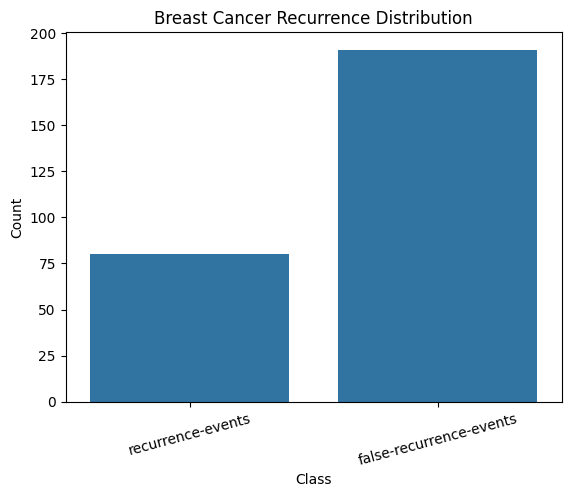

In [98]:
sns.countplot(data=df, x='class')

plt.title("Breast Cancer Recurrence Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=15)
plt.show()

Class Distribution:
class
false-recurrence-events    191
recurrence-events           80
Name: count, dtype: int64

Class Percentages:
class
false-recurrence-events    70.479705
recurrence-events          29.520295
Name: proportion, dtype: float64


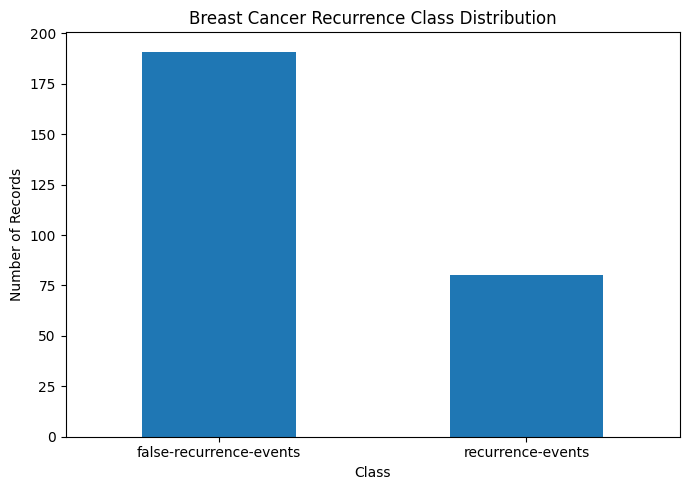

In [99]:
import pandas as pd
import matplotlib.pyplot as plt

# Count target classes
class_counts = df['class'].value_counts()

print("Class Distribution:")
print(class_counts)

# Calculate percentages
print("\nClass Percentages:")
print(df['class'].value_counts(normalize=True) * 100)

# Visualize class distribution
plt.figure(figsize=(7, 5))
class_counts.plot(kind='bar')

plt.title("Breast Cancer Recurrence Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Degree of Malignancy:
deg-malig
1.0     65
2.0    126
3.0     80
Name: count, dtype: int64

Statistical Summary:
count    271.000000
mean       2.055351
std        0.730727
min        1.000000
25%        2.000000
50%        2.000000
75%        3.000000
max        3.000000
Name: deg-malig, dtype: float64


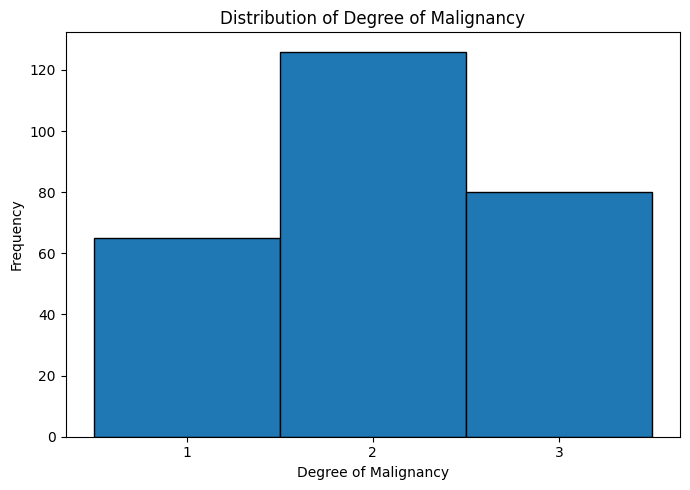

In [100]:
# Frequency distribution
print("Degree of Malignancy:")
print(df['deg-malig'].value_counts().sort_index())

# Statistical summary
print("\nStatistical Summary:")
print(df['deg-malig'].describe())

# Histogram
plt.figure(figsize=(7, 5))
plt.hist(df['deg-malig'], bins=[0.5, 1.5, 2.5, 3.5], edgecolor='black')

plt.title("Distribution of Degree of Malignancy")
plt.xlabel("Degree of Malignancy")
plt.ylabel("Frequency")
plt.xticks([1, 2, 3])
plt.tight_layout()
plt.show()


Distribution of age
age
50-59    92
40-49    86
60-69    53
30-39    34
70-79     5
20-29     1
Name: count, dtype: int64


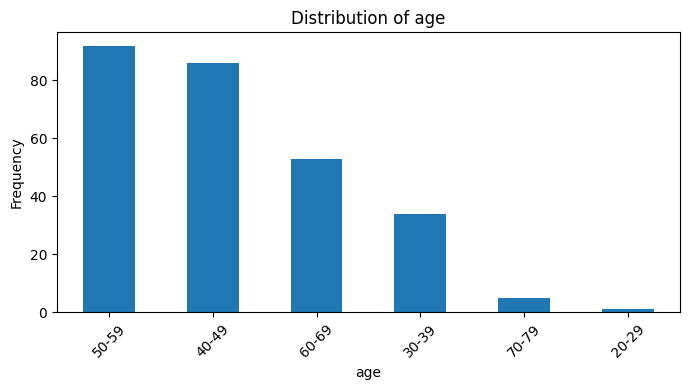


Distribution of mefalsepause
mefalsepause
premefalse    146
ge40          118
lt40            7
Name: count, dtype: int64


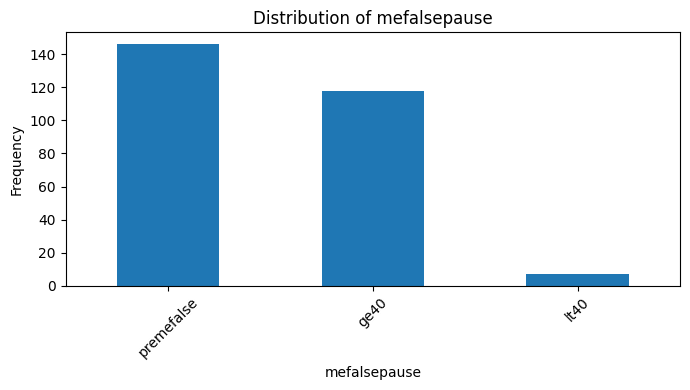


Distribution of breast
breast
left     142
right    129
Name: count, dtype: int64


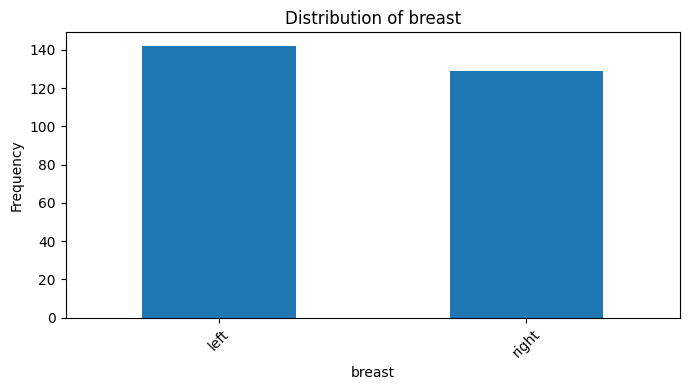


Distribution of breast-quad
breast-quad
left_low     104
left_up       92
right_up      32
right_low     23
central       20
Name: count, dtype: int64


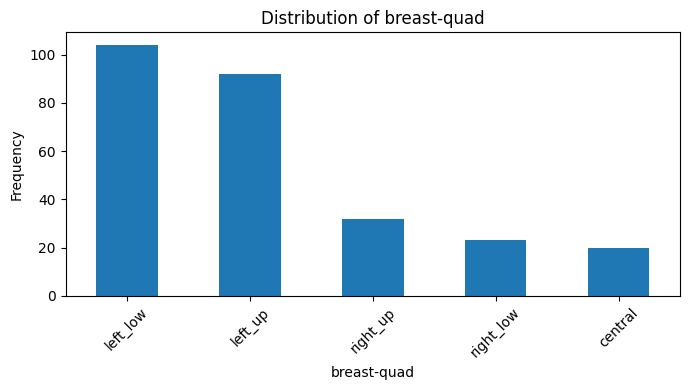


Distribution of irradiat
irradiat
False    204
True      67
Name: count, dtype: int64


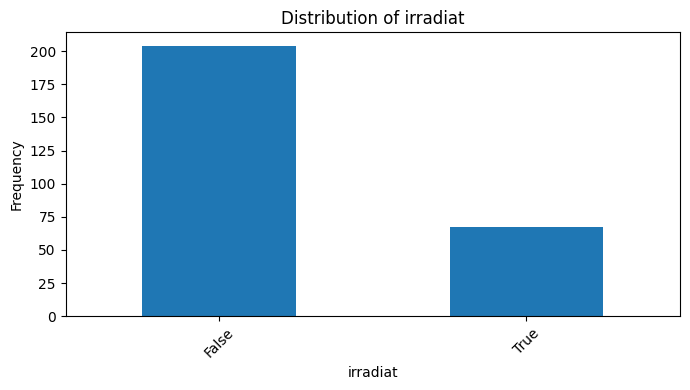

In [101]:
categorical_columns = [
    'age',
    'mefalsepause',
    'breast',
    'breast-quad',
    'irradiat'
]

for col in categorical_columns:
    print("\nDistribution of", col)
    print(df[col].value_counts())

    df[col].value_counts().plot(kind='bar', figsize=(7, 4))
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [102]:
print("Dataset Information:")
df.info()

print("\nCategorical Columns:")
print(df.select_dtypes(include='object').columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271 entries, 0 to 270
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           271 non-null    object 
 1   mefalsepause  271 non-null    object 
 2   tumor-size    271 non-null    object 
 3   inv-falsedes  271 non-null    object 
 4   falsede-caps  271 non-null    bool   
 5   deg-malig     271 non-null    float64
 6   breast        271 non-null    object 
 7   breast-quad   271 non-null    object 
 8   irradiat      271 non-null    object 
 9   class         271 non-null    object 
dtypes: bool(1), float64(1), object(8)
memory usage: 19.4+ KB

Categorical Columns:
['age', 'mefalsepause', 'tumor-size', 'inv-falsedes', 'breast', 'breast-quad', 'irradiat', 'class']


In [103]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

df_encoded = df.copy()

# Ordinal encoding
ordinal_columns = ['age', 'tumor-size', 'inv-falsedes']

for col in ordinal_columns:
    categories = sorted(df_encoded[col].unique())
    mapping = {value: index for index, value in enumerate(categories)}
    df_encoded[col] = df_encoded[col].map(mapping)

# One-hot encoding
one_hot_columns = [
    'mefalsepause',
    'breast',
    'breast-quad'
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=one_hot_columns,
    dtype=int
)

# Boolean and binary encoding
df_encoded['falsede-caps'] = df_encoded['falsede-caps'].astype(int)

df_encoded['irradiat'] = df_encoded['irradiat'].map({
    False: 0, True: 1,
    'False': 0, 'True': 1
})

# Target encoding
le = LabelEncoder()
df_encoded['class'] = le.fit_transform(df_encoded['class'])

print("Encoded Dataset Shape:", df_encoded.shape)
print(df_encoded.head())
print("\nData Types:")
print(df_encoded.dtypes)

Encoded Dataset Shape: (271, 17)
   age  tumor-size  inv-falsedes  falsede-caps  deg-malig  irradiat  class  \
0    2           2             0             1        3.0         0      1   
1    3           2             0             0        1.0         0      0   
2    3           6             0             0        2.0         0      1   
3    2           6             0             1        3.0         1      0   
4    2           5             4             1        2.0         0      1   

   mefalsepause_ge40  mefalsepause_lt40  mefalsepause_premefalse  breast_left  \
0                  0                  0                        1            0   
1                  1                  0                        0            0   
2                  1                  0                        0            1   
3                  0                  0                        1            0   
4                  0                  0                        1            1   

   breast_r

In [104]:
for col in ['age', 'tumor-size', 'inv-falsedes']:
    categories = sorted(
        df[col].unique(),
        key=lambda x: int(str(x).split('-')[0])
    )

    mapping = {value: index for index, value in enumerate(categories)}

    print(f"\n{col} Encoding Mapping:")
    print(mapping)


age Encoding Mapping:
{'20-29': 0, '30-39': 1, '40-49': 2, '50-59': 3, '60-69': 4, '70-79': 5}

tumor-size Encoding Mapping:
{'0-4': 0, '5-9': 1, '10-14': 2, '15-19': 3, '20-24': 4, '25-29': 5, '30-34': 6, '35-39': 7, '40-44': 8, '45-49': 9, '50-54': 10}

inv-falsedes Encoding Mapping:
{'0-2': 0, '3-5': 1, '6-8': 2, '9-11': 3, '12-14': 4, '15-17': 5, '24-26': 6}


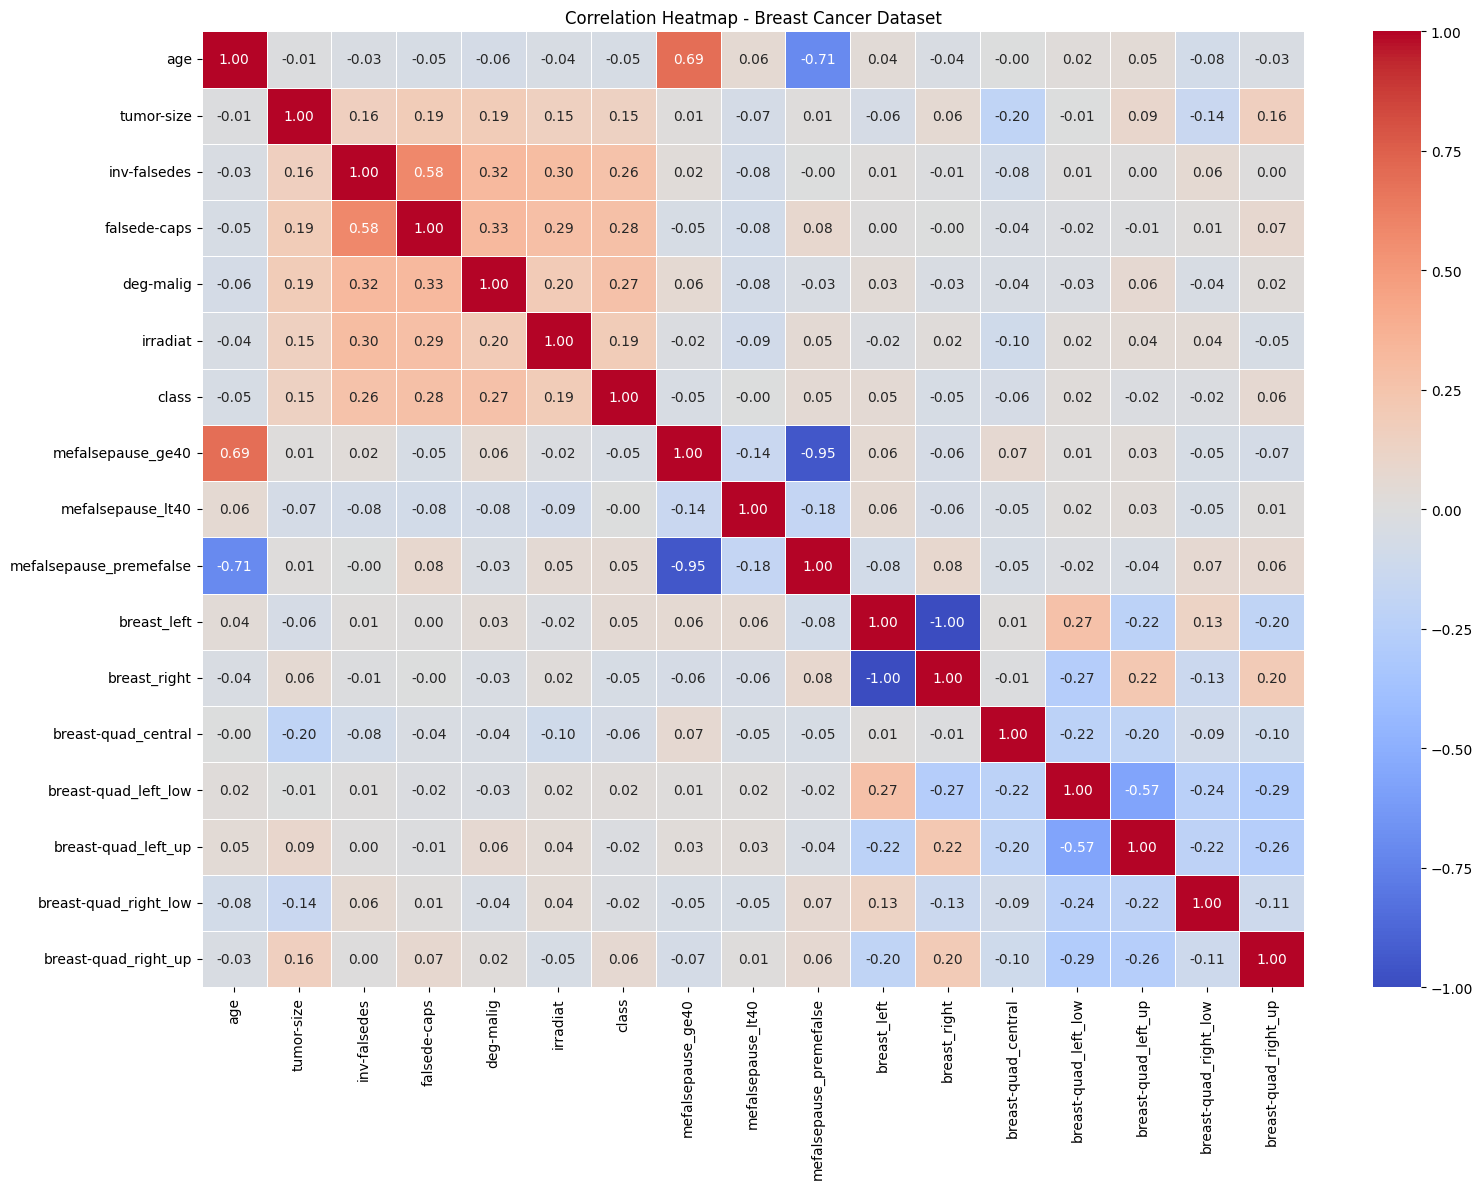

In [105]:


import seaborn as sns
import matplotlib.pyplot as plt

df_encoded = df.copy()

# Correct ordinal encoding
ordinal_columns = ['age', 'tumor-size', 'inv-falsedes']

for col in ordinal_columns:
    categories = sorted(
        df_encoded[col].unique(),
        key=lambda x: int(x.split('-')[0])
    )

    mapping = {value: index for index, value in enumerate(categories)}
    df_encoded[col] = df_encoded[col].map(mapping)

# One-hot encoding
df_encoded = pd.get_dummies(
    df_encoded,
    columns=['mefalsepause', 'breast', 'breast-quad'],
    dtype=int
)

# Binary encoding
df_encoded['falsede-caps'] = df_encoded['falsede-caps'].astype(int)

df_encoded['irradiat'] = df_encoded['irradiat'].map({
    'False': 0, 'True': 1,
    False: 0, True: 1
})

# Target encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_encoded['class'] = le.fit_transform(df_encoded['class'])

# Correlation matrix
correlation_matrix = df_encoded.corr()

# Heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap - Breast Cancer Dataset")
plt.tight_layout()
plt.show()

                    Feature  Importance
1                tumor-size    0.249329
4                 deg-malig    0.131190
0                       age    0.119219
2              inv-falsedes    0.100338
3              falsede-caps    0.056343
5                  irradiat    0.056107
13      breast-quad_left_up    0.041807
9               breast_left    0.038106
10             breast_right    0.035224
12     breast-quad_left_low    0.033592
15     breast-quad_right_up    0.031115
6         mefalsepause_ge40    0.029872
8   mefalsepause_premefalse    0.029613
11      breast-quad_central    0.018519
14    breast-quad_right_low    0.017861
7         mefalsepause_lt40    0.011766


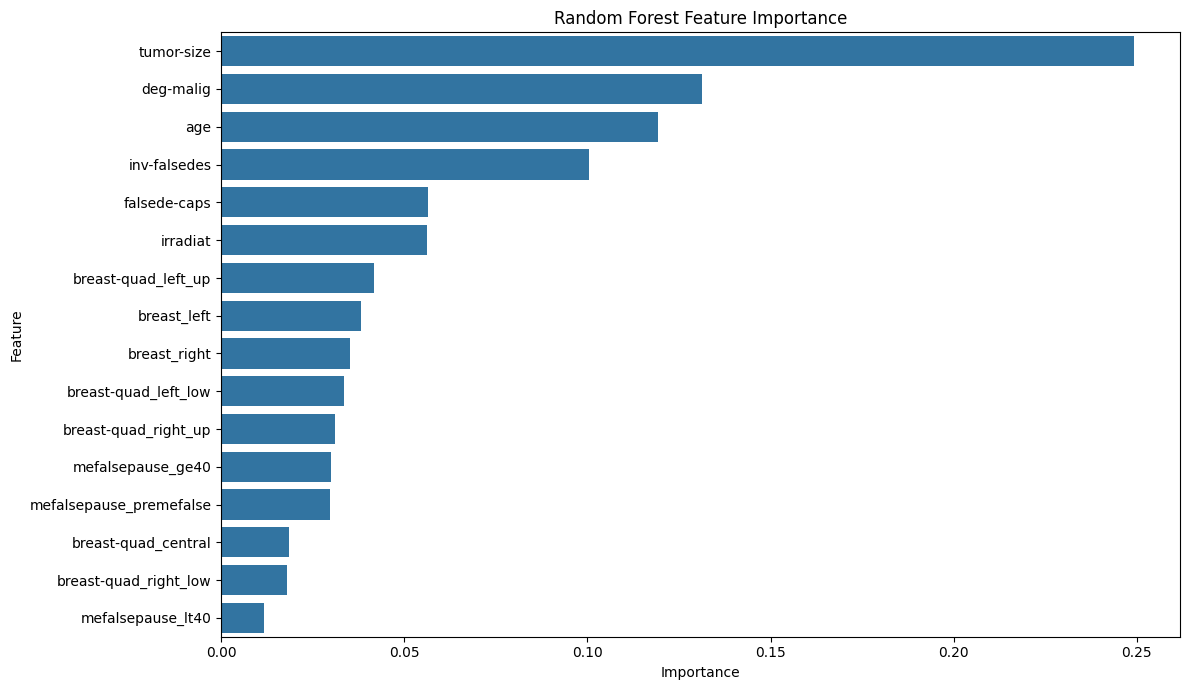

In [106]:
from sklearn.ensemble import RandomForestClassifier

# Separate input features and target
X = df_encoded.drop('class', axis=1)
y = df_encoded['class']

# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X, y)

# Calculate feature importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

# Sort features
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

# Visualize feature importance
plt.figure(figsize=(12, 7))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [107]:
# Select top 10 features
top_features = importance.head(10)['Feature'].tolist()

print("Selected Features:")
print(top_features)

# Create selected dataset
X_selected = df_encoded[top_features]

# Target variable
y = df_encoded['class']

print("\nSelected Dataset Shape:", X_selected.shape)
print("Target Shape:", y.shape)

Selected Features:
['tumor-size', 'deg-malig', 'age', 'inv-falsedes', 'falsede-caps', 'irradiat', 'breast-quad_left_up', 'breast_left', 'breast_right', 'breast-quad_left_low']

Selected Dataset Shape: (271, 10)
Target Shape: (271,)


In [108]:

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data Shape: (216, 10)
Testing Data Shape: (55, 10)

Training Class Distribution:
class
0    152
1     64
Name: count, dtype: int64

Testing Class Distribution:
class
0    39
1    16
Name: count, dtype: int64


In [109]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create Logistic Regression model
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluate model
print("Logistic Regression Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results

Accuracy: 0.6909090909090909

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.87      0.80        39
           1       0.44      0.25      0.32        16

    accuracy                           0.69        55
   macro avg       0.59      0.56      0.56        55
weighted avg       0.65      0.69      0.66        55


Confusion Matrix:
[[34  5]
 [12  4]]


In [110]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create KNN model
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=5,
        weights='distance'
    )
)

# Train model
knn_model.fit(X_train, y_train)

# Predictions
y_pred_knn = knn_model.predict(X_test)

# Evaluation
print("KNN Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN Results

Accuracy: 0.6363636363636364

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.77      0.75        39
           1       0.36      0.31      0.33        16

    accuracy                           0.64        55
   macro avg       0.54      0.54      0.54        55
weighted avg       0.62      0.64      0.63        55


Confusion Matrix:
[[30  9]
 [11  5]]


In [111]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=None
)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluation
print("Random Forest Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results

Accuracy: 0.6545454545454545

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.79      0.77        39
           1       0.38      0.31      0.34        16

    accuracy                           0.65        55
   macro avg       0.56      0.55      0.56        55
weighted avg       0.64      0.65      0.64        55


Confusion Matrix:
[[31  8]
 [11  5]]


In [112]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create SVM model
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel='rbf',
        C=1,
        class_weight='balanced',
        random_state=42
    )
)

# Train model
svm_model.fit(X_train, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test)

# Evaluation
print("SVM Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM Results

Accuracy: 0.6181818181818182

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.69      0.72        39
           1       0.37      0.44      0.40        16

    accuracy                           0.62        55
   macro avg       0.56      0.56      0.56        55
weighted avg       0.64      0.62      0.63        55


Confusion Matrix:
[[27 12]
 [ 9  7]]


                 Model  Accuracy  Recall  F1 Score
0  Logistic Regression  0.690909    0.25      0.32
1                  KNN  0.636364    0.31      0.33
2        Random Forest  0.654545    0.31      0.34
3                  SVM  0.618182    0.44      0.40


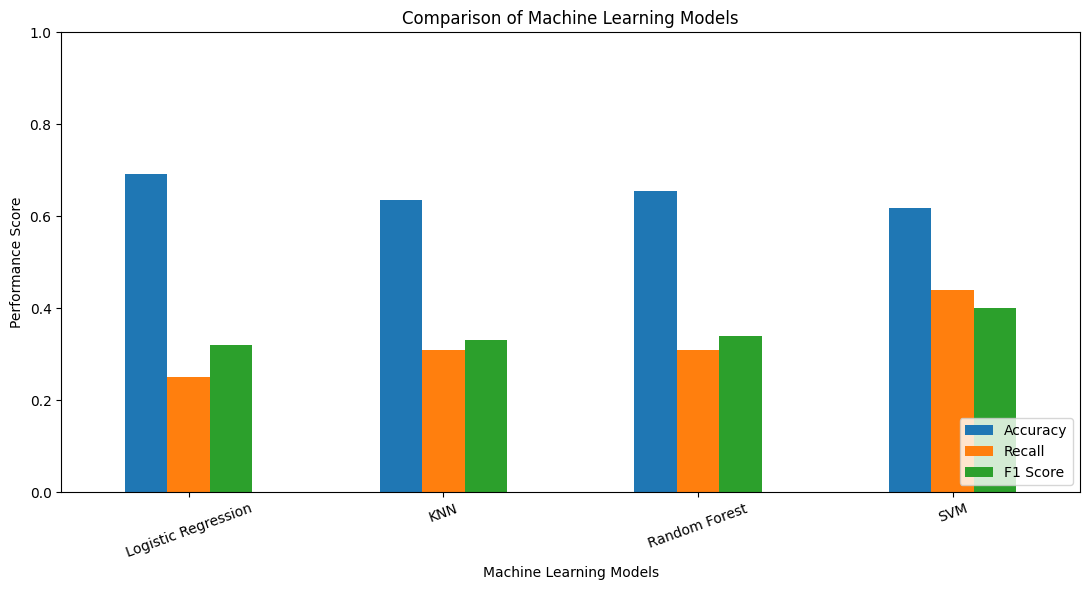

In [113]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Recall': [
        0.25, 0.31, 0.31, 0.44
    ],
    'F1 Score': [
        0.32, 0.33, 0.34, 0.40
    ]
})

print(results)

results.set_index('Model').plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [114]:

# Step 1: Prepare features and target

import pandas as pd
import numpy as np

# Use the original cleaned dataset, NOT df_encoded or X_selected
data = df.copy()

# Convert binary columns into consistent strings
for col in ['falsede-caps', 'irradiat']:
    data[col] = data[col].astype(str).str.strip().str.lower()

# Separate features and target
X = data.drop(columns=['class'])

y = data['class'].map({
    'false-recurrence-events': 0,
    'recurrence-events': 1
})

# Check the data
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing Values:")
print(X.isnull().sum())

print("\nTarget Distribution:")
print(y.value_counts())


Feature Shape: (271, 9)
Target Shape: (271,)

Missing Values:
age             0
mefalsepause    0
tumor-size      0
inv-falsedes    0
falsede-caps    0
deg-malig       0
breast          0
breast-quad     0
irradiat        0
dtype: int64

Target Distribution:
class
0    191
1     80
Name: count, dtype: int64


In [115]:

# Step 2: Check unique values in categorical columns

categorical_columns = [
    'age',
    'mefalsepause',
    'tumor-size',
    'inv-falsedes',
    'falsede-caps',
    'breast',
    'breast-quad',
    'irradiat'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(sorted(X[col].astype(str).unique()))



age:
['20-29', '30-39', '40-49', '50-59', '60-69', '70-79']

mefalsepause:
['ge40', 'lt40', 'premefalse']

tumor-size:
['0-4', '10-14', '15-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49', '5-9', '50-54']

inv-falsedes:
['0-2', '12-14', '15-17', '24-26', '3-5', '6-8', '9-11']

falsede-caps:
['false', 'true']

breast:
['left', 'right']

breast-quad:
['central', 'left_low', 'left_up', 'right_low', 'right_up']

irradiat:
['false', 'true']


In [116]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Define ordinal features and their correct order
ordinal_features = ['age', 'tumor-size', 'inv-falsedes']

ordinal_categories = [
    ['20-29', '30-39', '40-49', '50-59', '60-69', '70-79'],
    ['0-4', '5-9', '10-14', '15-19', '20-24',
     '25-29', '30-34', '35-39', '40-44', '45-49', '50-54'],
    ['0-2', '3-5', '6-8', '9-11', '12-14', '15-17', '24-26']
]

# 2. Define nominal features
nominal_features = ['mefalsepause', 'breast', 'breast-quad']

# 3. Define binary features
binary_features = ['falsede-caps', 'irradiat']

# 4. Build preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('ordinal', OrdinalEncoder(
            categories=ordinal_categories
        ), ordinal_features),

        ('nominal', OneHotEncoder(
            handle_unknown='ignore',
            drop='if_binary'
        ), nominal_features),

        ('binary', OrdinalEncoder(
            categories=[['false', 'true'], ['false', 'true']]
        ), binary_features),

        ('numeric', 'passthrough', ['deg-malig'])
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [117]:

from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier

# Feature selection using Random Forest
selector = SelectFromModel(
    estimator=RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    threshold='median'
)

print("Feature selector created successfully!")


Feature selector created successfully!


In [118]:

from sklearn.model_selection import StratifiedKFold

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation created!")

# Check fold sizes
for fold, (train_index, test_index) in enumerate(cv.split(X, y), 1):
    print(
        f"Fold {fold}: "
        f"Training samples = {len(train_index)}, "
        f"Validation samples = {len(test_index)}"
    )


Stratified 5-Fold Cross-Validation created!
Fold 1: Training samples = 216, Validation samples = 55
Fold 2: Training samples = 217, Validation samples = 54
Fold 3: Training samples = 217, Validation samples = 54
Fold 4: Training samples = 217, Validation samples = 54
Fold 5: Training samples = 217, Validation samples = 54


In [119]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate
import pandas as pd

# Define four models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5,
        weights='distance'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ),

    'SVM': SVC(
        kernel='rbf',
        C=1,
        class_weight='balanced',
        random_state=42
    )
}

# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

results = []

# Evaluate each model
for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('feature_selection', selector),
        ('scaling', StandardScaler()),
        ('model', model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean()
    })

# Display comparison
results_df = pd.DataFrame(results)

print("5-Fold Cross-Validation Results:")
print(results_df.round(4))


5-Fold Cross-Validation Results:
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.6568     0.4380  0.5875    0.4995   0.6847
1                  KNN    0.6274     0.3184  0.2500    0.2776   0.5238
2        Random Forest    0.6089     0.3112  0.2625    0.2844   0.5820
3                  SVM    0.6347     0.3945  0.4500    0.4191   0.6309


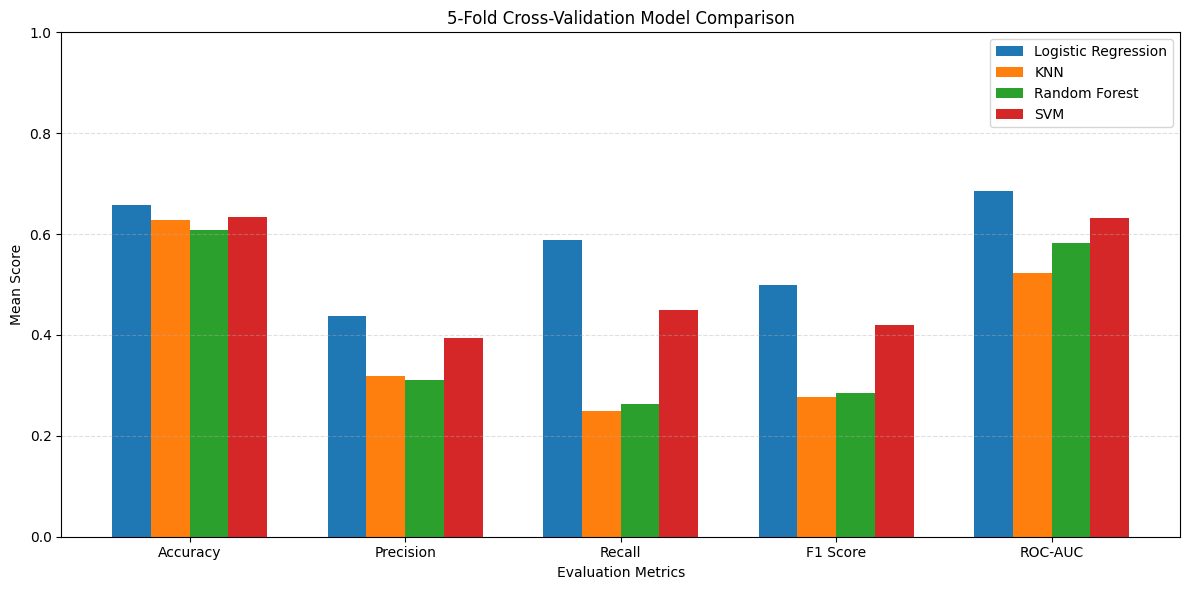

In [120]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

x = np.arange(len(metrics))
width = 0.18

plt.figure(figsize=(12, 6))

for i, row in results_df.iterrows():
    values = [row[m] for m in metrics]

    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=row['Model']
    )

plt.xlabel('Evaluation Metrics')
plt.ylabel('Mean Score')
plt.title('5-Fold Cross-Validation Model Comparison')

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


In [121]:

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

summary = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('feature_selection', selector),
        ('scaling', StandardScaler()),
        ('model', model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {'Model': name}

    for metric in scoring:
        values = scores[f'test_{metric}']

        row[f'{metric}_mean'] = values.mean()
        row[f'{metric}_std'] = values.std(ddof=1)

    summary.append(row)

summary_df = pd.DataFrame(summary)

print("Mean and Standard Deviation of 5-Fold CV:")
print(summary_df.round(4).to_string(index=False))


Mean and Standard Deviation of 5-Fold CV:
              Model  accuracy_mean  accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  roc_auc_mean  roc_auc_std
Logistic Regression         0.6568        0.0382          0.4380         0.0494       0.5875      0.1218   0.4995  0.0710        0.6847       0.0318
                KNN         0.6274        0.0624          0.3184         0.1347       0.2500      0.1466   0.2776  0.1411        0.5238       0.0775
      Random Forest         0.6089        0.0297          0.3112         0.0479       0.2625      0.0280   0.2844  0.0353        0.5820       0.0457
                SVM         0.6347        0.0576          0.3945         0.0814       0.4500      0.1202   0.4191  0.0952        0.6309       0.0841


In [122]:

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', selector),
    ('scaling', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Define hyperparameter combinations
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced'],
    'model__solver': ['lbfgs']
}

# Apply GridSearchCV
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# Train and tune
grid_search.fit(X, y)

# Display results
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters:
{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}

Best Cross-Validation F1 Score:
0.5287


In [123]:

from sklearn.model_selection import cross_validate

best_lr = grid_search.best_estimator_

tuned_scores = cross_validate(
    best_lr,
    X,
    y,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1',
        'roc_auc': 'roc_auc'
    },
    n_jobs=-1
)

print("Tuned Logistic Regression Results:")

for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    values = tuned_scores[f'test_{metric}']
    print(
        f"{metric.upper()}: "
        f"Mean = {values.mean():.4f}, "
        f"Std = {values.std(ddof=1):.4f}"
    )


Tuned Logistic Regression Results:
ACCURACY: Mean = 0.6864, Std = 0.0408
PRECISION: Mean = 0.4775, Std = 0.0535
RECALL: Mean = 0.6000, Std = 0.1046
F1: Mean = 0.5287, Std = 0.0607
ROC_AUC: Mean = 0.6955, Std = 0.0313


In [124]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# KNN pipeline
knn_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', selector),
    ('scaling', StandardScaler()),
    ('model', KNeighborsClassifier())
])

# Hyperparameter grid
knn_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 13],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan']
}

# GridSearchCV
knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# Train
knn_search.fit(X, y)

print("Best KNN Parameters:")
print(knn_search.best_params_)

print("\nBest KNN F1 Score:")
print(round(knn_search.best_score_, 4))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best KNN Parameters:
{'model__metric': 'manhattan', 'model__n_neighbors': 13, 'model__weights': 'uniform'}

Best KNN F1 Score:
0.3713


In [125]:
best_knn = knn_search.best_estimator_

knn_scores = cross_validate(
    best_knn,
    X,
    y,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1',
        'roc_auc': 'roc_auc'
    },
    n_jobs=-1
)

print("Tuned KNN Results")

for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    values = knn_scores[f'test_{metric}']
    print(
        f"{metric}: {values.mean():.4f} "
        f"+/- {values.std():.4f}"
    )

Tuned KNN Results
accuracy: 0.7378 +/- 0.0496
precision: 0.6714 +/- 0.2421
recall: 0.2625 +/- 0.0829
f1: 0.3713 +/- 0.1087
roc_auc: 0.6514 +/- 0.0657


In [126]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', selector),
    ('scaling', StandardScaler()),
    ('model', RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ))
])

rf_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X, y)

print("Best Random Forest Parameters:")
print(rf_search.best_params_)

print("\nBest Random Forest F1 Score:")
print(round(rf_search.best_score_, 4))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Random Forest Parameters:
{'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Best Random Forest F1 Score:
0.4682


In [127]:
best_rf = rf_search.best_estimator_

rf_scores = cross_validate(
    best_rf,
    X,
    y,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1',
        'roc_auc': 'roc_auc'
    },
    n_jobs=-1
)

print("Tuned Random Forest Results")

for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    values = rf_scores[f'test_{metric}']

    print(
        f"{metric}: {values.mean():.4f} "
        f"+/- {values.std():.4f}"
    )

Tuned Random Forest Results
accuracy: 0.6901 +/- 0.0371
precision: 0.4802 +/- 0.0670
recall: 0.4625 +/- 0.0637
f1: 0.4682 +/- 0.0522
roc_auc: 0.6657 +/- 0.0487


In [128]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', selector),
    ('scaling', StandardScaler()),
    ('model', SVC(
        kernel='rbf',
        class_weight='balanced',
        probability=True,
        random_state=42
    ))
])

svm_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

svm_search.fit(X, y)

print("Best SVM Parameters:")
print(svm_search.best_params_)

print("\nBest SVM F1 Score:")
print(round(svm_search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best SVM Parameters:
{'model__C': 0.1, 'model__gamma': 'scale'}

Best SVM F1 Score:
0.4972


In [129]:
best_svm = svm_search.best_estimator_

svm_scores = cross_validate(
    best_svm,
    X,
    y,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1',
        'roc_auc': 'roc_auc'
    },
    n_jobs=-1
)

print("Tuned SVM Results")

for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    values = svm_scores[f'test_{metric}']

    print(
        f"{metric}: {values.mean():.4f} "
        f"+/- {values.std():.4f}"
    )

Tuned SVM Results
accuracy: 0.6496 +/- 0.0243
precision: 0.4321 +/- 0.0319
recall: 0.5875 +/- 0.0500
f1: 0.4972 +/- 0.0334
roc_auc: 0.6954 +/- 0.0517


In [130]:
import joblib

final_model = grid_search.best_estimator_

joblib.dump(final_model, 'final_breast_cancer_model.pkl')

print("Final Logistic Regression model saved successfully!")

Final Logistic Regression model saved successfully!


In [131]:
from google.colab import files

files.download('final_breast_cancer_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [132]:
final_model = grid_search.best_estimator_

final_model.fit(X, y)

print("Final Logistic Regression Model Trained Successfully!")

Final Logistic Regression Model Trained Successfully!


Confusion Matrix:
[[138  53]
 [ 32  48]]

Classification Report:
                  precision    recall  f1-score   support

False Recurrence       0.81      0.72      0.76       191
      Recurrence       0.48      0.60      0.53        80

        accuracy                           0.69       271
       macro avg       0.64      0.66      0.65       271
    weighted avg       0.71      0.69      0.70       271



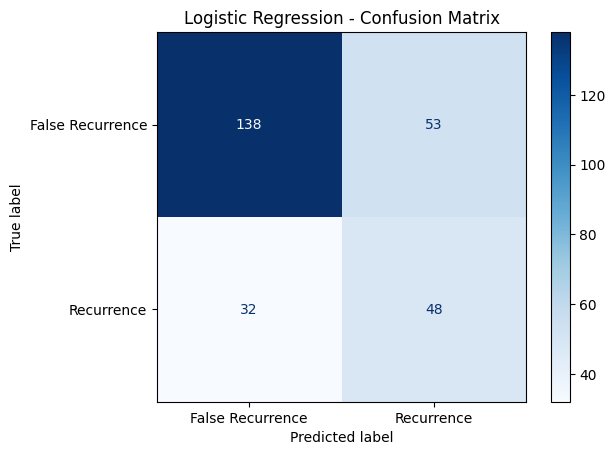

In [133]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate cross-validation predictions
y_pred = cross_val_predict(
    final_model,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

# Confusion Matrix
cm = confusion_matrix(y, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y,
    y_pred,
    target_names=[
        'False Recurrence',
        'Recurrence'
    ]
))

# Visualize Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        'False Recurrence',
        'Recurrence'
    ]
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

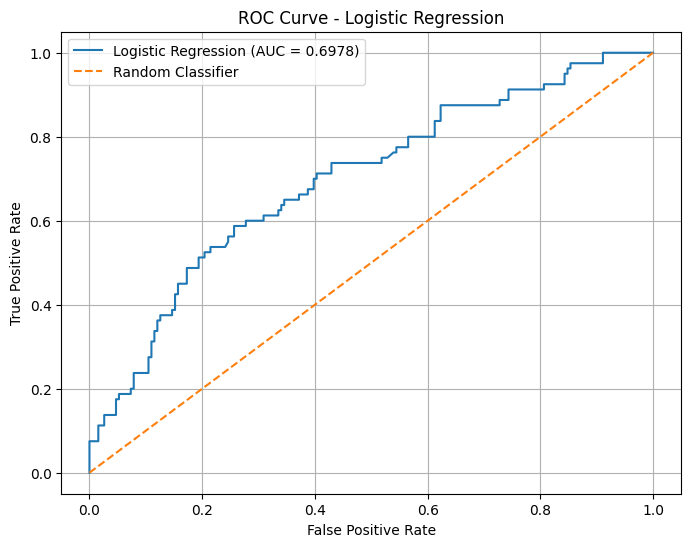

ROC-AUC Score: 0.6978


In [134]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get cross-validation probabilities
y_prob = cross_val_predict(
    final_model,
    X,
    y,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y, y_prob)
roc_auc = roc_auc_score(y, y_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

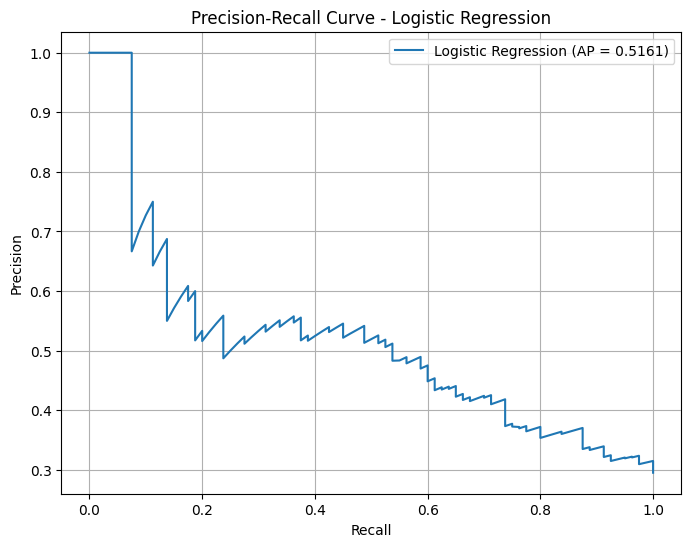

Average Precision Score: 0.5161


In [135]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Calculate Precision-Recall values
precision, recall, thresholds = precision_recall_curve(
    y,
    y_prob
)

# Calculate Average Precision
avg_precision = average_precision_score(y, y_prob)

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f'Logistic Regression (AP = {avg_precision:.4f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Logistic Regression')

plt.legend()
plt.grid()
plt.show()

print("Average Precision Score:", round(avg_precision, 4))

Feature Importance:
                     Feature  Coefficient  Importance
          numeric__deg-malig     0.180567    0.180567
        binary__falsede-caps     0.149852    0.149852
       ordinal__inv-falsedes     0.136661    0.136661
            binary__irradiat     0.112040    0.112040
         ordinal__tumor-size     0.102398    0.102398
                ordinal__age    -0.037312    0.037312
       nominal__breast_right    -0.034274    0.034274
nominal__breast-quad_left_up    -0.011140    0.011140


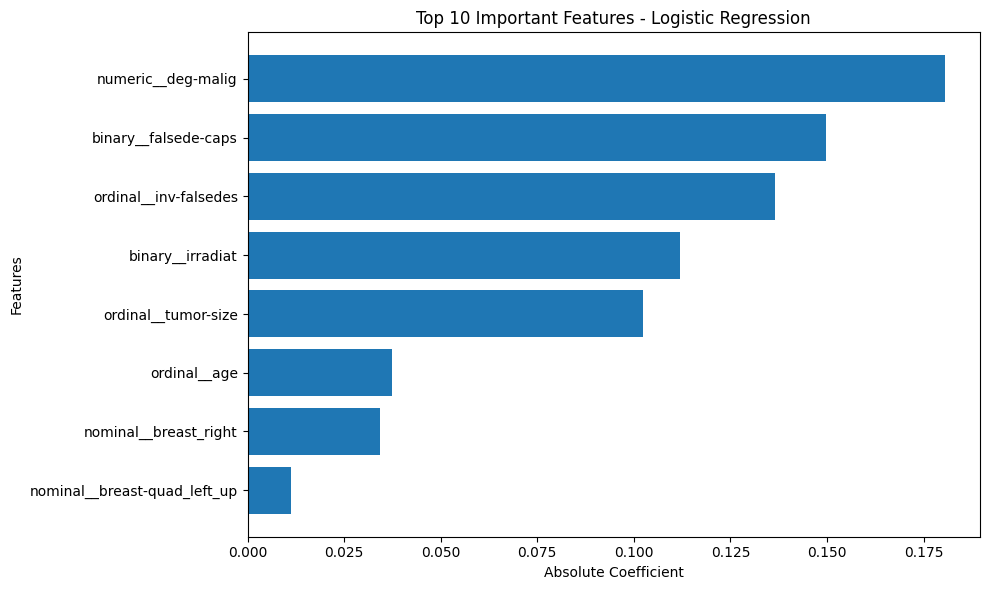

In [136]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = (
    final_model
    .named_steps['preprocessing']
    .get_feature_names_out()
)

# Get selected features
selected_mask = (
    final_model
    .named_steps['feature_selection']
    .get_support()
)

selected_features = feature_names[selected_mask]

# Get Logistic Regression coefficients
coefficients = (
    final_model
    .named_steps['model']
    .coef_[0]
)

# Create feature importance dataframe
importance_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': coefficients,
    'Importance': abs(coefficients)
})

# Sort by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
print(importance_df.to_string(index=False))

# Plot top 10 features
top_features = importance_df.head(10).sort_values(
    'Importance'
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Absolute Coefficient')
plt.ylabel('Features')
plt.title('Top 10 Important Features - Logistic Regression')
plt.tight_layout()
plt.show()

In [137]:
import joblib

# Save the trained model
joblib.dump(
    final_model,
    'final_breast_cancer_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [138]:
from google.colab import files

files.download('final_breast_cancer_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [139]:
import pandas as pd

def predict_recurrence(patient_data):

    # Convert input into DataFrame
    new_patient = pd.DataFrame([patient_data])

    # Predict class
    prediction = final_model.predict(new_patient)[0]

    # Get prediction probability
    probabilities = final_model.predict_proba(new_patient)[0]

    if prediction == 1:
        result = "Recurrence"
    else:
        result = "False Recurrence"

    print("Prediction:", result)
    print("Recurrence probability:", round(probabilities[1] * 100, 2), "%")
    print("False recurrence probability:", round(probabilities[0] * 100, 2), "%")

    return result

In [140]:
sample_patient = {
    'age': '40-49',
    'mefalsepause': 'premefalse',
    'tumor-size': '20-24',
    'inv-falsedes': '0-2',
    'falsede-caps': 'false',
    'deg-malig': 2,
    'breast': 'left',
    'breast-quad': 'left_up',
    'irradiat': 'false'
}

predict_recurrence(sample_patient)

Prediction: False Recurrence
Recurrence probability: 42.8 %
False recurrence probability: 57.2 %


'False Recurrence'